# Esercizio 08.1 — Variational Monte Carlo

Si considera una particella quantistica in una dimensione soggetta al potenziale

$$
V(x)=x^4-\frac{5}{2}x^2.
$$

Lo scopo dell'esercizio è stimare l'energia dello stato fondamentale mediante il metodo
**Variational Monte Carlo (VMC)**, combinando il principio variazionale della meccanica
quantistica con il campionamento Metropolis.

## Principio variazionale

Il principio variazionale afferma che, per una generica funzione d'onda di prova
$\Psi_T(x)$,

$$
\langle H\rangle_T =
\frac{\langle\Psi_T|\hat H|\Psi_T\rangle}
{\langle\Psi_T|\Psi_T\rangle}
\geq E_0,
$$

dove $E_0$ rappresenta l'energia dello stato fondamentale.

Una buona approssimazione dello stato fondamentale può quindi essere ottenuta
introducendo una funzione d'onda dipendente da alcuni parametri variazionali e
cercando i valori che minimizzano $\langle H\rangle_T$.

La funzione d'onda di prova utilizzata è

$$
\Psi_T^{\mu,\sigma}(x)=
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
+
e^{-\frac{(x+\mu)^2}{2\sigma^2}},
$$

dove $\mu$ controlla la posizione dei due contributi gaussiani e $\sigma$ ne
determina la larghezza.

## Energia locale

L'energia variazionale può essere scritta come

$$
\langle H\rangle_T =
\frac{\int dx\,\Psi_T^*(x)\hat H\Psi_T(x)}
{\int dx\,|\Psi_T(x)|^2}.
$$

Introducendo la distribuzione di probabilità

$$
p(x)=
\frac{|\Psi_T(x)|^2}
{\int dx\,|\Psi_T(x)|^2}
$$

e definendo l'energia locale come

$$
E_{\mathrm{loc}}(x)=
\frac{\hat H\Psi_T(x)}
{\Psi_T(x)},
$$

si ottiene

$$
\langle H\rangle_T =
\int dx\,p(x)E_{\mathrm{loc}}(x).
$$

Con $\hbar=1$ e $m=1$, l'Hamiltoniana è

$$
\hat H=
-\frac{1}{2}\frac{d^2}{dx^2}+V(x),
$$

per cui

$$
E_{\mathrm{loc}}(x)=
-\frac{1}{2}
\frac{\Psi_T''(x)}{\Psi_T(x)}
+
x^4-\frac{5}{2}x^2.
$$

La stima dell'energia variazionale viene quindi ricondotta al calcolo del valore
medio dell'energia locale rispetto alla distribuzione $p(x)$.

## Campionamento Metropolis

La distribuzione $p(x)$ viene campionata mediante l'algoritmo di Metropolis.

A partire dalla posizione corrente $x_{\mathrm{old}}$, viene proposta una nuova
posizione secondo

$$
x_{\mathrm{new}} =
x_{\mathrm{old}}+\delta,
$$

dove $\delta$ è estratto uniformemente nell'intervallo $[-\Delta,\Delta]$.

Poiché la probabilità di transizione è simmetrica, la probabilità di accettazione
del nuovo punto è

$$
A(x_{\mathrm{new}}|x_{\mathrm{old}})
=
\min
\left[
1,
\frac{|\Psi_T(x_{\mathrm{new}})|^2}
{|\Psi_T(x_{\mathrm{old}})|^2}
\right].
$$

Dopo l'equilibrazione, la catena di Markov genera una sequenza

$$
x_1,x_2,\ldots,x_M
$$

distribuita secondo $p(x)\propto|\Psi_T(x)|^2$.

L'integrale che definisce l'energia variazionale può quindi essere stimato mediante

$$
\boxed{
\langle H\rangle_T
\simeq
\frac{1}{M}
\sum_{i=1}^{M}
E_{\mathrm{loc}}(x_i)
}.
$$

Il fattore $p(x)$ non deve essere inserito esplicitamente nella somma, poiché il suo
peso è già incorporato nella frequenza con cui le diverse regioni dello spazio
vengono visitate dall'algoritmo di Metropolis.

## Data blocking

Le configurazioni successive generate dal Metropolis non sono completamente
indipendenti. Per ottenere una stima affidabile dell'incertezza statistica,
le misure dell'energia locale vengono suddivise in blocchi.

Per ogni blocco viene calcolata la media

$$
A_j=
\frac{1}{L}
\sum_{i=1}^{L}
E_{\mathrm{loc}}(x_i),
$$

dove $L$ è il numero di passi contenuti nel blocco.

La stima finale dell'energia viene quindi ottenuta dalla media delle medie di blocco,

$$
\langle H\rangle_T
\simeq
\frac{1}{N}
\sum_{j=1}^{N}A_j,
$$

mentre la dispersione delle medie di blocco permette di stimare l'incertezza
statistica associata al risultato.

## Parametri della simulazione

Per la prima simulazione vengono utilizzati i parametri variazionali

$$
\mu=1,
\qquad
\sigma=0.5.
$$

Questi valori rappresentano una configurazione iniziale e non corrispondono
necessariamente ai parametri ottimali.

La simulazione utilizza:

- $N=10^3$ blocchi;
- $L=10^3$ passi Metropolis per blocco;
- $2000$ passi iniziali di equilibrazione;
- semilarghezza della proposta uniforme $\Delta=1.2$; con questa scelta si ottiene un accettanza del circa 50.3 %.

Il numero totale di misure utilizzate per la stima dell'energia è quindi

$$
M=N\cdot L=10^6.
$$

In [15]:
import numpy as np
import matplotlib.pyplot as plt
# Lettura dei risultati prodotti dalla simulazione C++

data = np.loadtxt("Esercizio_08.1/energy.txt")

blocks = data[:, 0]
block_energy = data[:, 1]
progressive_energy = data[:, 2]
error = data[:, 3]

print(f"Energia finale = {progressive_energy[-1]:.6f} ± {error[-1]:.6f}")

Energia finale = -0.147261 ± 0.001586


## Energia variazionale progressiva

La media progressiva permette di osservare la convergenza della stima
dell'energia all'aumentare del numero di blocchi.

Le barre d'errore rappresentano l'incertezza statistica ottenuta mediante
data blocking.

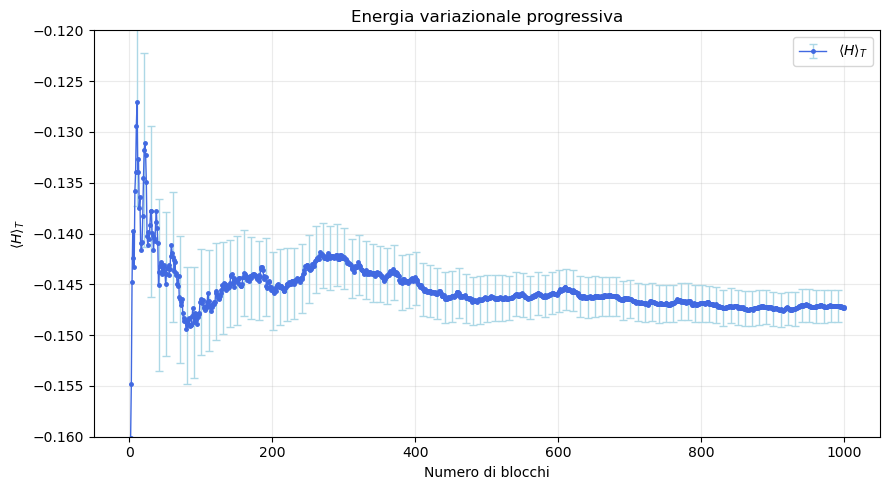

In [24]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks,
    progressive_energy,
    yerr=error,
    fmt='o-',
    markersize=2.5,
    linewidth=1,
    capsize=3,
    color='royalblue',
    ecolor='lightblue',
    errorevery=10,
    label=r"$\langle H \rangle_T$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle H \rangle_T$")
plt.ylim(-0.16, -0.12)
plt.title("Energia variazionale progressiva")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

### Risultati

Per i parametri variazionali

$$
\mu=1,
\qquad
\sigma=0.5,
$$

si ottiene

$$
\boxed{
\langle H\rangle_T =
-0.147261 \pm 0.001586
}.
$$

Il tasso di accettazione dell'algoritmo di Metropolis è pari a circa

$$
50.3\%.
$$

Il valore ottenuto indica un buon bilanciamento tra passi accettati e rifiutati,
per cui il valore $\Delta=1.2$ utilizzato per la proposta uniforme risulta
adeguato.

La media progressiva tende a stabilizzarsi all'aumentare del numero di blocchi
e l'incertezza statistica diminuisce progressivamente.

L'energia ottenuta rappresenta un upper bound variazionale dell'energia dello
stato fondamentale. I parametri $\mu$ e $\sigma$ non sono ancora ottimizzati;
la loro minimizzazione verrà affrontata nell'esercizio 08.2.

## Distribuzione campionata

Le posizioni generate dalla catena di Markov devono essere distribuite secondo

$$
p(x)=
\frac{|\Psi_T(x)|^2}
{\int dx\,|\Psi_T(x)|^2}.
$$

Il corretto funzionamento del campionamento Metropolis può essere verificato
confrontando l'istogramma delle posizioni generate numericamente con la
distribuzione analitica normalizzata $|\Psi_T(x)|^2$.

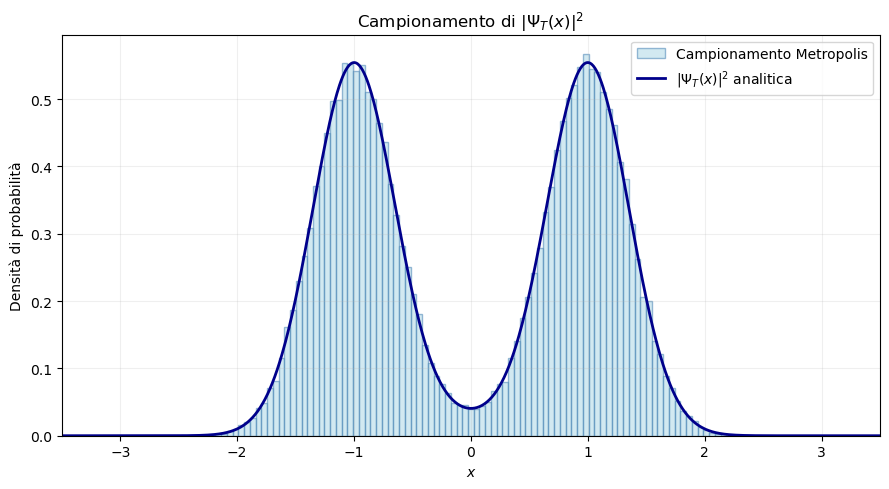

In [20]:
# Lettura delle posizioni campionate

samples = np.loadtxt("Esercizio_08.1/samples.txt")

mu = 1
sigma = 0.5


# Funzione d'onda di prova

def psi(x, mu, sigma):
    return (
        np.exp(-(x - mu)**2 / (2 * sigma**2))
        +
        np.exp(-(x + mu)**2 / (2 * sigma**2))
    )


# Intervallo utilizzato per rappresentare la distribuzione teorica

x = np.linspace(-3.5, 3.5, 1000)


# Densità di probabilità non normalizzata

psi2 = psi(x, mu, sigma)**2


# Normalizzazione numerica

normalization = np.trapezoid(psi2, x)

probability = psi2 / normalization

plt.figure(figsize=(9, 5))

plt.hist(
    samples,
    bins=100,
    density=True,
    alpha=0.55,
    color="lightblue",
    edgecolor="steelblue",
    label="Campionamento Metropolis"
)

plt.plot(
    x,
    probability,
    color="darkblue",
    linewidth=2,
    label=r"$|\Psi_T(x)|^2$ analitica"
)

plt.xlabel("$x$")
plt.ylabel("Densità di probabilità")
plt.title(r"Campionamento di $|\Psi_T(x)|^2$")

plt.xlim(-3.5, 3.5)

plt.grid(alpha=0.20)
plt.legend()

plt.tight_layout()
plt.show()

### Confronto tra distribuzione teorica e campionamento

L'istogramma delle configurazioni generate dal Metropolis riproduce la forma
della distribuzione teorica $|\Psi_T(x)|^2$.

La presenza di due regioni maggiormente popolate deriva dalla struttura della
funzione d'onda di prova, costituita dalla somma di due gaussiane centrate
rispettivamente in $+\mu$ e $-\mu$.

L'accordo tra l'istogramma e la curva teorica conferma che la catena di Markov
campiona correttamente la distribuzione richiesta dal metodo Variational
Monte Carlo.

# Esercizio 08.2 — Simulated Annealing

Nell'esercizio precedente l'energia variazionale

$$
\langle H\rangle_T
$$

è stata calcolata per valori fissati dei parametri $\mu$ e $\sigma$.

Lo scopo di questa parte è determinare i valori dei parametri variazionali che
minimizzano l'energia mediante un algoritmo di **Simulated Annealing (SA)**.

La funzione costo del problema è quindi

$$
L(\mu,\sigma)=\langle H\rangle_T.
$$

Ogni valutazione della funzione costo viene ottenuta mediante una simulazione
Variational Monte Carlo.

## Simulated Annealing

Nel Simulated Annealing la funzione costo viene interpretata come l'energia di
un sistema statistico alla temperatura fittizia $T$.

A partire dalla configurazione corrente $(\mu,\sigma)$ viene proposta una nuova
configurazione

$$
\mu'=\mu+\delta_\mu,
$$

$$
\sigma'=\sigma+\delta_\sigma,
$$

con $\delta_\mu$ e $\delta_\sigma$ estratti uniformemente in intervalli fissati.

Per le due configurazioni vengono calcolate le energie variazionali

$$
E_{\mathrm{old}}=
\langle H\rangle_{\mu,\sigma},
$$

$$
E_{\mathrm{new}}=
\langle H\rangle_{\mu',\sigma'}.
$$

Si definisce quindi

$$
\Delta E =
E_{\mathrm{new}}-E_{\mathrm{old}}.
$$

Se $\Delta E\leq0$, la nuova configurazione viene sempre accettata.

Se $\Delta E>0$, la configurazione viene accettata con probabilità

$$
P =
e^{-\Delta E/T}.
$$

A temperature elevate possono quindi essere accettate anche configurazioni
peggiori, permettendo una maggiore esplorazione dello spazio dei parametri.
Diminuendo progressivamente la temperatura, l'algoritmo tende invece a
concentrarsi nelle regioni caratterizzate da energia minore.

## Schedule di temperatura

È stata utilizzata una legge di raffreddamento geometrica

$$
T_{n+1}=\alpha T_n,
$$

con

$$
T_0=0.10,
\qquad
\alpha=0.98.
$$

Sono stati eseguiti $200$ passi di Simulated Annealing.

I parametri iniziali sono

$$
\mu_0=1.0,
\qquad
\sigma_0=0.5,
$$

mentre le ampiezze delle proposte nello spazio variazionale sono

$$
\Delta_\mu=0.10,
\qquad
\Delta_\sigma=0.10.
$$

Per ogni configurazione proposta, l'energia viene stimata tramite Variational
Monte Carlo utilizzando $100$ blocchi da $2000$ passi ciascuno.

In [25]:
# Lettura dell'evoluzione del Simulated Annealing

sa = np.loadtxt("Esercizio_08.2/annealing.txt")

step = sa[:, 0]
temperature = sa[:, 1]
mu_sa = sa[:, 2]
sigma_sa = sa[:, 3]
energy_sa = sa[:, 4]
error_sa = sa[:, 5]
accepted_sa = sa[:, 6]
best_energy_sa = sa[:, 7]

print(f"Numero di passi SA: {len(step)-1}")
print(f"Accettazione SA: {100*np.mean(accepted_sa[1:]):.1f} %")

Numero di passi SA: 200
Accettazione SA: 29.5 %


## Evoluzione dell'energia durante il Simulated Annealing

L'andamento di $\langle H\rangle_T$ durante il Simulated Annealing permette di
osservare il progressivo spostamento verso regioni dello spazio variazionale
caratterizzate da energia più bassa.

Ogni valore di energia è ottenuto tramite una simulazione Monte Carlo ed è
quindi associato a un'incertezza statistica.

Per mantenere leggibile il grafico, le barre d'errore vengono rappresentate
solo ogni $10$ passi.

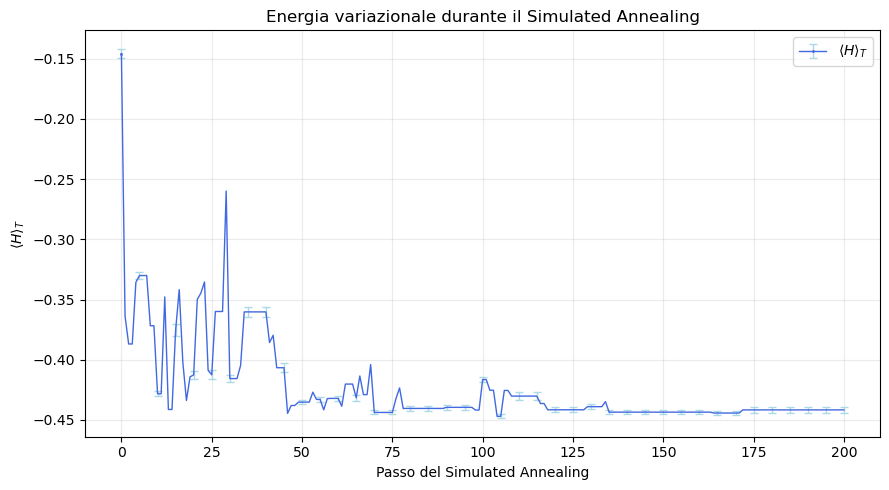

In [41]:
plt.figure(figsize=(9, 5))

plt.errorbar(
    step,
    energy_sa,
    yerr=error_sa,
    fmt='-o',
    linewidth=1,
    markersize=1,
    markevery=500,
    errorevery=5,
    capsize=3,
    color='royalblue',
    ecolor='lightblue',
    label=r"$\langle H\rangle_T$"
)

plt.xlabel("Passo del Simulated Annealing")
plt.ylabel(r"$\langle H\rangle_T$")
plt.title("Energia variazionale durante il Simulated Annealing")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

### Andamento dell'ottimizzazione

L'energia iniziale, corrispondente a

$$
\mu=1.0,
\qquad
\sigma=0.5,
$$

è circa

$$
\langle H\rangle_T\simeq-0.146.
$$

Durante il Simulated Annealing l'energia diminuisce rapidamente e successivamente
oscilla nella regione del minimo.

Le oscillazioni sono dovute sia all'accettazione probabilistica di configurazioni
a energia maggiore sia all'incertezza statistica associata alle singole
valutazioni Variational Monte Carlo.

A basse temperature le configurazioni peggiorative vengono accettate con
probabilità sempre minore e il sistema tende a rimanere nella regione di minimo.

## Traiettoria nello spazio dei parametri

L'evoluzione dei parametri $\mu$ e $\sigma$ può essere rappresentata direttamente
nel piano variazionale.

La traiettoria mostra il passaggio dalla configurazione iniziale

$$
(\mu,\sigma)=(1.0,0.5)
$$

alla regione individuata dal Simulated Annealing come minimo dell'energia
variazionale.

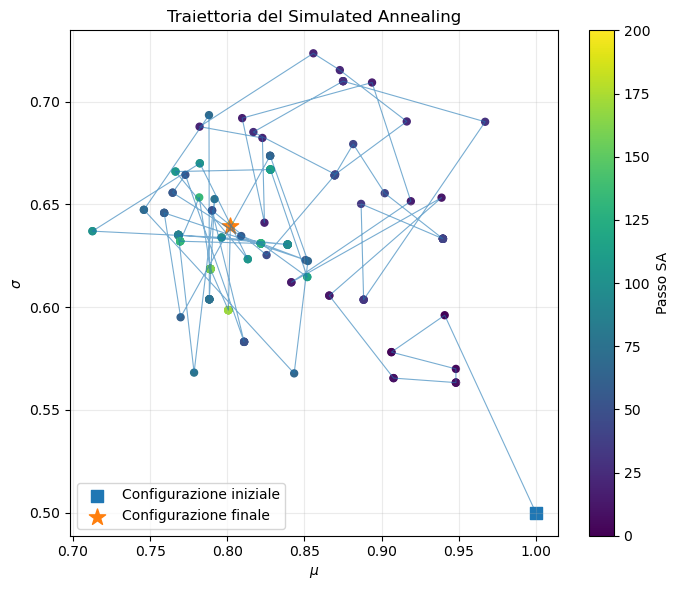

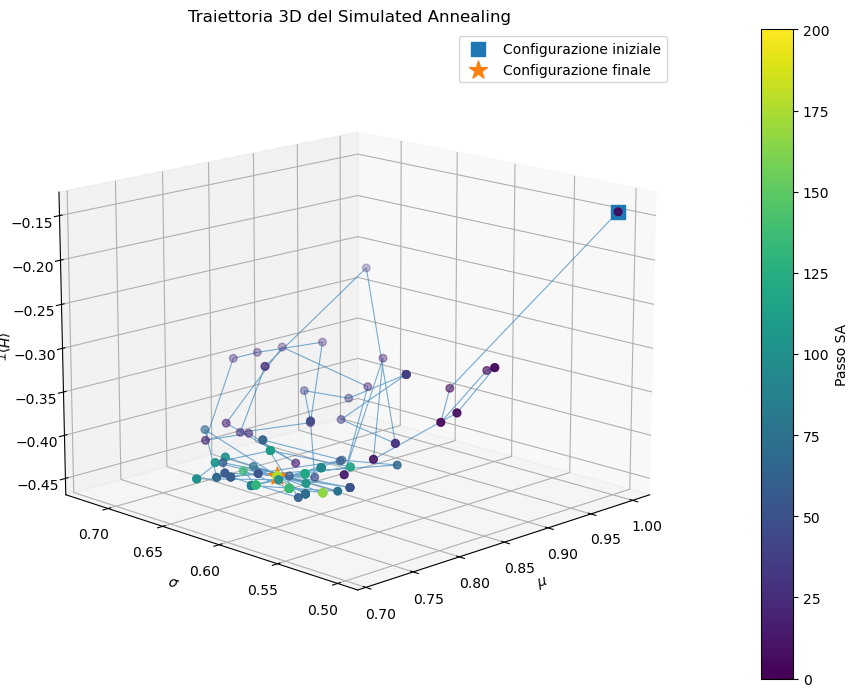

In [53]:
plt.figure(figsize=(7, 6))

plt.plot(
    mu_sa,
    sigma_sa,
    '-',
    linewidth=0.8,
    alpha=0.6
)

sc = plt.scatter(
    mu_sa,
    sigma_sa,
    c=step,
    cmap='viridis',
    s=25
)

plt.scatter(
    mu_sa[0],
    sigma_sa[0],
    marker='s',
    s=80,
    label="Configurazione iniziale"
)

plt.scatter(
    mu_sa[-1],
    sigma_sa[-1],
    marker='*',
    s=150,
    label="Configurazione finale"
)

plt.xlabel(r"$\mu$")
plt.ylabel(r"$\sigma$")
plt.title("Traiettoria del Simulated Annealing")

plt.colorbar(sc, label="Passo SA")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()



from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(9, 7))

ax = fig.add_subplot(111, projection='3d')


# Traiettoria del Simulated Annealing

ax.plot(
    mu_sa,
    sigma_sa,
    energy_sa,
    '-',
    linewidth=0.8,
    alpha=0.6
)


# Punti colorati in funzione dello step SA

sc = ax.scatter(
    mu_sa,
    sigma_sa,
    energy_sa,
    c=step,
    cmap='viridis',
    s=30
)


# Configurazione iniziale

ax.scatter(
    mu_sa[0],
    sigma_sa[0],
    energy_sa[0],
    marker='s',
    s=100,
    label="Configurazione iniziale"
)


# Configurazione finale

ax.scatter(
    mu_sa[-1],
    sigma_sa[-1],
    energy_sa[-1],
    marker='*',
    s=180,
    label="Configurazione finale"
)


ax.set_xlabel(r"$\mu$")
ax.set_ylabel(r"$\sigma$")
ax.set_zlabel(r"$\langle H\rangle_T$")
ax.view_init(elev=15, azim=225)
ax.set_title(
    "Traiettoria 3D del Simulated Annealing"
)


# Barra dei colori associata al numero dello step

fig.colorbar(
    sc,
    ax=ax,
    pad=0.1,
    label="Passo SA"
)


ax.legend()

plt.tight_layout()
plt.show()
plt.show()

In [54]:
# Lettura dei parametri ottimizzati e del risultato finale

best = np.loadtxt("Esercizio_08.2/best_parameters.txt")

mu_opt = best[0]
sigma_opt = best[1]
energy_opt = best[2]
error_opt = best[3]
acceptance_opt = best[4]

print(f"mu ottimizzato    = {mu_opt:.6f}")
print(f"sigma ottimizzato = {sigma_opt:.6f}")
print(f"<H> finale        = {energy_opt:.6f} ± {error_opt:.6f}")
print(f"Accettazione      = {100*acceptance_opt:.2f} %")

mu ottimizzato    = 0.813292
sigma ottimizzato = 0.623367
<H> finale        = -0.442106 ± 0.000902
Accettazione      = 53.25 %


## Parametri variazionali ottimizzati

Il Simulated Annealing individua una regione di minimo caratterizzata da

$$
\boxed{
\mu\simeq0.813,
\qquad
\sigma\simeq0.623
}.
$$

Utilizzando questi parametri viene eseguita una nuova simulazione Variational
Monte Carlo ad alta statistica, con $1000$ blocchi da $1000$ passi ciascuno.

La stima finale dell'energia è

$$
\boxed{
\langle H\rangle_T=
-0.442106\pm0.000902
}.
$$

L'accettazione dell'algoritmo di Metropolis nella simulazione finale è pari a

$$
53.25\%.
$$

Il valore dell'energia registrato come minimo durante il Simulated Annealing
può risultare leggermente inferiore alla successiva stima ad alta statistica,
poiché ogni valutazione della funzione costo è affetta da fluttuazioni Monte Carlo.
La simulazione finale fornisce quindi la stima più affidabile dell'energia
corrispondente ai parametri ottimizzati.

## Energia finale e data blocking

La simulazione finale viene analizzata mediante data blocking.

La media progressiva dell'energia permette di verificare la convergenza della
stima ottenuta con i parametri variazionali ottimizzati.

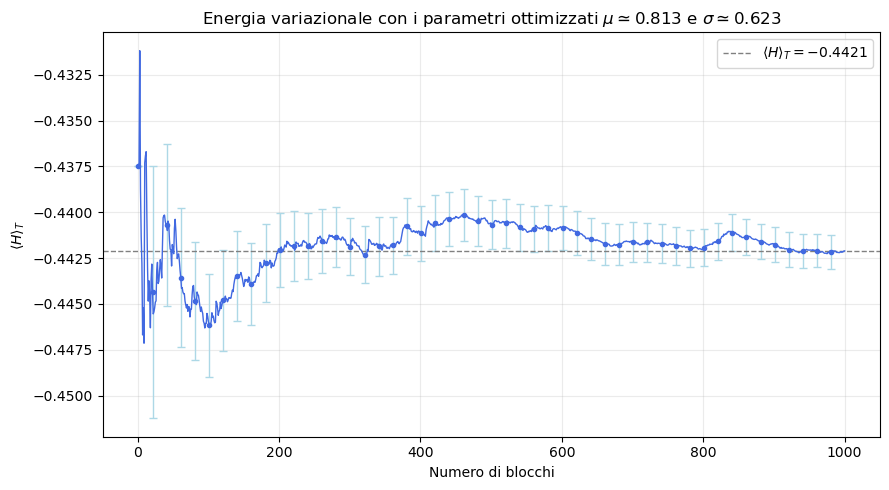

In [52]:
final_data = np.loadtxt("Esercizio_08.2/final_energy.txt")

blocks_final = final_data[:, 0]
block_energy_final = final_data[:, 1]
progressive_energy_final = final_data[:, 2]
error_final = final_data[:, 3]

plt.figure(figsize=(9, 5))

plt.errorbar(
    blocks_final,
    progressive_energy_final,
    yerr=error_final,
    fmt='-o',
    linewidth=1,
    markersize=3,
    markevery=20,
    errorevery=20,
    capsize=3,
    color='royalblue',
    ecolor='lightblue'
)

plt.axhline(
    energy_opt,
    linestyle='--',
    linewidth=1,
    color='gray',
    label=fr"$\langle H\rangle_T={energy_opt:.4f}$"
)

plt.xlabel("Numero di blocchi")
plt.ylabel(r"$\langle H\rangle_T$")
plt.title("Energia variazionale con i parametri ottimizzati $\mu\simeq 0.813$ e $\sigma\simeq0.623$")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()
plt.show()

## Distribuzione di probabilità ottimizzata

Le configurazioni campionate nella simulazione finale sono distribuite secondo

$$
p(x)=
\frac{|\Psi_T^{\mu,\sigma}(x)|^2}
{\int dx\,|\Psi_T^{\mu,\sigma}(x)|^2}.
$$

L'istogramma delle configurazioni Monte Carlo viene confrontato con la densità
di probabilità analitica ottenuta dalla funzione d'onda di prova utilizzando i
parametri ottimizzati.

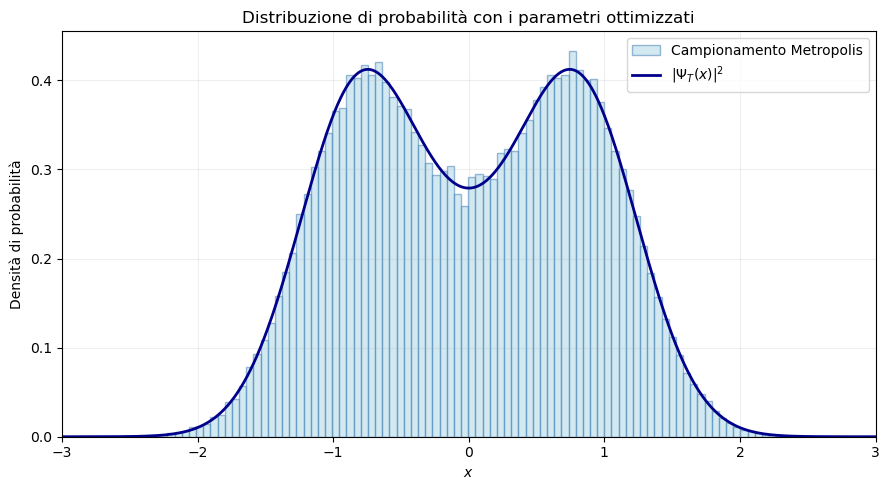

In [36]:
samples = np.loadtxt("Esercizio_08.2/final_samples.txt")


def psi(x, mu, sigma):
    
    return (
        np.exp(-(x - mu)**2 / (2 * sigma**2))
        +
        np.exp(-(x + mu)**2 / (2 * sigma**2))
    )


x = np.linspace(-3.0, 3.0, 1500)

psi2 = psi(x, mu_opt, sigma_opt)**2

normalization = np.trapezoid(psi2, x)

probability = psi2 / normalization

plt.figure(figsize=(9, 5))

plt.hist(
    samples,
    bins=100,
    density=True,
    alpha=0.55,
    color="lightblue",
    edgecolor="steelblue",
    label="Campionamento Metropolis"
)

plt.plot(
    x,
    probability,
    color="darkblue",
    linewidth=2,
    label=r"$|\Psi_T(x)|^2$"
)

plt.xlabel("$x$")
plt.ylabel("Densità di probabilità")
plt.title("Distribuzione di probabilità con i parametri ottimizzati")

plt.xlim(-3.0, 3.0)

plt.grid(alpha=0.20)
plt.legend()

plt.tight_layout()
plt.show()

## Soluzione numerica dell'equazione di Schrödinger

La funzione d'onda variazionale può essere confrontata con una soluzione numerica
dell'equazione di Schrödinger indipendente dal tempo,

$$
\hat H\Psi(x)=E\Psi(x).
$$

Con $\hbar=1$ e $m=1$, l'Hamiltoniana è

$$
\hat H=
-\frac{1}{2}\frac{d^2}{dx^2}+V(x).
$$

Lo spazio viene discretizzato su una griglia di punti separati da una distanza
$dx$. La derivata seconda viene approssimata mediante il metodo delle differenze
centrali,

$$
\frac{d^2\Psi}{dx^2}\bigg|_{x_i}
\simeq
\frac{\Psi_{i+1}-2\Psi_i+\Psi_{i-1}}{dx^2}.
$$

L'operatore Hamiltoniano viene quindi rappresentato mediante una matrice.
La diagonalizzazione di questa matrice permette di ottenere gli autovalori
dell'energia e le corrispondenti autofunzioni.

L'autovettore associato all'autovalore più basso rappresenta lo stato
fondamentale numerico del sistema.

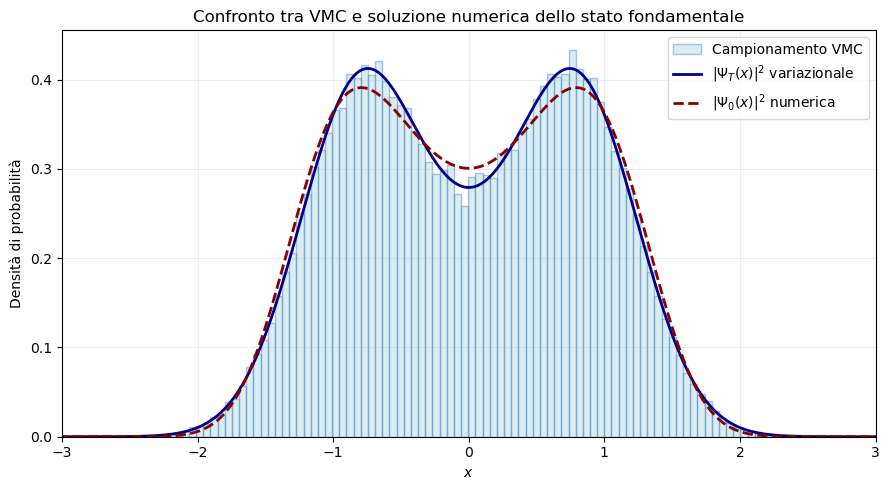

In [48]:
# Soluzione numerica dell'equazione di Schrödinger
# mediante discretizzazione dell'Hamiltoniana

def Vpot(x):
    return (x**2 - 2.5) * x**2


hbar = 1.0
m = 1.0

N = 1000


# Griglia spaziale

x_num = np.linspace(-3/2, 3/2, N)

dx = x_num[1] - x_num[0]


# Potenziale

V_num = Vpot(x_num)


# Matrice della derivata seconda con differenze centrali
#
# f''(x_i) ≃ [f_(i+1) - 2f_i + f_(i-1)] / dx^2

CDiff = (
    np.diag(np.ones(N - 1), -1)
    - 2 * np.diag(np.ones(N), 0)
    + np.diag(np.ones(N - 1), 1)
)


# Matrice Hamiltoniana

H = (
    -(hbar**2) * CDiff / (2 * m * dx**2)
    + np.diag(V_num)
)


# Calcolo degli autovalori e degli autovettori

E, psi_num = np.linalg.eigh(H)


# np.linalg.eigh restituisce gli autovettori per colonne.
# La trasposizione permette di indicizzare gli stati come psi_num[n].

psi_num = np.transpose(psi_num)


# Normalizzazione rispetto all'integrale continuo

psi_num = psi_num / np.sqrt(dx)



# Soluzione numerica dell'equazione di Schrödinger
# mediante discretizzazione dell'Hamiltoniana

def Vpot(x):
    return (x**2 - 2.5) * x**2


hbar = 1.0
m = 1.0

a = 10
N = 1000


# Griglia spaziale

x_num = np.linspace(-3*a/2, 3*a/2, N)

dx = x_num[1] - x_num[0]


# Potenziale

V_num = Vpot(x_num)


# Matrice della derivata seconda con differenze centrali

CDiff = (
    np.diag(np.ones(N - 1), -1)
    - 2 * np.diag(np.ones(N), 0)
    + np.diag(np.ones(N - 1), 1)
)


# Matrice Hamiltoniana

H = (
    -(hbar**2) * CDiff / (2 * m * dx**2)
    + np.diag(V_num)
)


# Autovalori e autovettori

E, psi_num = np.linalg.eigh(H)


# Gli autovettori sono restituiti per colonne

psi_num = np.transpose(psi_num)


# Normalizzazione continua

psi_num = psi_num / np.sqrt(dx)




plt.figure(figsize=(9, 5))

plt.hist(
    samples,
    bins=100,
    density=True,
    alpha=0.45,
    color="lightblue",
    edgecolor="steelblue",
    label="Campionamento VMC"
)

plt.plot(
    x,
    probability_trial,
    color="darkblue",
    linewidth=2,
    label=r"$|\Psi_T(x)|^2$ variazionale"
)

plt.plot(
    x_num,
    psi_num[0]**2,
    color="darkred",
    linewidth=2,
    linestyle="--",
    label=r"$|\Psi_0(x)|^2$ numerica"
)

plt.xlabel("$x$")
plt.ylabel("Densità di probabilità")

plt.title(
    "Confronto tra VMC e soluzione numerica dello stato fondamentale"
)

# Il calcolo numerico viene effettuato su [-15, 15],
# ma viene visualizzata soltanto la regione fisicamente rilevante.

plt.xlim(-3.0, 3.0)

plt.grid(alpha=0.20)
plt.legend()

plt.tight_layout()
plt.show()

### Confronto con la soluzione numerica

La distribuzione ottenuta tramite il campionamento VMC riproduce correttamente
la densità di probabilità associata alla funzione d'onda variazionale
$|\Psi_T(x)|^2$.

La soluzione numerica dell'equazione di Schrödinger presenta una forma molto
simile, con due regioni di maggiore probabilità simmetriche rispetto all'origine.

La principale differenza è visibile nella regione centrale, dove la soluzione
numerica presenta una probabilità leggermente maggiore rispetto alla funzione
d'onda variazionale.

La diagonalizzazione numerica dell'Hamiltoniana fornisce

$$
E_0 \simeq -0.4605,
$$

mentre il Variational Monte Carlo fornisce

$$
\langle H\rangle_T =
-0.442106 \pm 0.000902.
$$

Il valore dell'energia ottenuto tramite il metodo variazionale risulta leggermente superiore all'energia dello stato fondamentale numerico, in perfetto accordo con il principio variazionale,

$$
\langle H\rangle_T \geq E_0.
$$

La differenza residua è dovuta al fatto che l'ottimizzazione viene effettuata all'interno della famiglia limitata di funzioni d'onda scelta come ansatz variazionale.
